# **People Flow Detection & Spatial Foot-Traffic Analysis**
### Real-Time Computer Vision Pipeline: YOLOv8 Object Detection, ByteTrack Multi-Object Tracking, Dual Virtual Tripwires, and Gaussian Heatmap Synthesis

This notebook implements an end-to-end computer vision pipeline for real-time bidirectional pedestrian counting and spatial density analysis.

---
### **Core Architecture**
- **Detector:** YOLOv8 Nano (`yolov8n.pt`) fine-tuned for high-FPS edge inference, filtered to COCO `class_id == 0` (person).
- **Tracker:** ByteTrack stateful association via `supervision`, maintaining consistent identity trajectories across visual occlusions.
- **Directional Tripwires:** Dual horizontal virtual counting lines at 40% (IN line) and 75% (OUT line) frame height with anti-double-counting state tracking.
- **Continuous Heatmap:** Float32 spatial accumulator applying 2D Gaussian kernel smoothing (sigma=20) and OpenCV Jet colormap alpha-blending.


## 1. Install Dependencies


In [1]:
!pip install -q -U ultralytics supervision opencv-python numpy matplotlib


## 2. Import Libraries & Configure Cross-Platform Utilities


In [2]:
import os
import urllib.request
import cv2
import matplotlib.pyplot as plt
import numpy as np
import supervision as sv
import torch
from ultralytics import YOLO

# Cross-platform display helper compatible with JupyterLab, VS Code, Google Colab, and headless environments
try:
    from google.colab.patches import cv2_imshow
except ImportError:
    def cv2_imshow(img):
        plt.figure(figsize=(10, 6))
        if len(img.shape) == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap="gray")
        plt.axis("off")
        plt.show()


## 3. Acquire Benchmark Video Stream


In [3]:
VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
SOURCE_VIDEO_PATH = "people-walking.mp4"
OUTPUT_VIDEO_PATH = "people_flow_output.mp4"

if not os.path.exists(SOURCE_VIDEO_PATH):
    print("Downloading sample video...")
    urllib.request.urlretrieve(VIDEO_URL, SOURCE_VIDEO_PATH)
    print("Video download complete.")
else:
    print(f"Source video already present: {SOURCE_VIDEO_PATH}")


Video already exists.


## 4. Inspect Video Stream Geometry & Metadata


In [4]:
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
print(f"Width: {video_info.width}, Height: {video_info.height}, "
      f"FPS: {video_info.fps}, Total frames: {video_info.total_frames}")


Width: 1920, Height: 1080, FPS: 25.0, Total frames: 341


## 5. Configure Virtual Counting Gates (Tripwires)

- **Upper Gate (Green - IN):** Horizontal tripwire placed at y = 0.40 * H. Triggers when a person moves downward through the line (prev_y < y_upper <= curr_y).
- **Lower Gate (Red - OUT):** Horizontal tripwire placed at y = 0.75 * H. Triggers when a person moves upward through the line (prev_y > y_lower >= curr_y).


In [5]:
FRAME_WIDTH = video_info.width
FRAME_HEIGHT = video_info.height

# Upper line (IN line)
LINE_UPPER_Y = int(FRAME_HEIGHT * 0.40)
LINE_UPPER_START = sv.Point(0, LINE_UPPER_Y)
LINE_UPPER_END = sv.Point(FRAME_WIDTH, LINE_UPPER_Y)

# Lower line (OUT line)
LINE_LOWER_Y = int(FRAME_HEIGHT * 0.75)
LINE_LOWER_START = sv.Point(0, LINE_LOWER_Y)
LINE_LOWER_END = sv.Point(FRAME_WIDTH, LINE_LOWER_Y)

print(f"Upper (IN) line y  = {LINE_UPPER_Y}")
print(f"Lower (OUT) line y = {LINE_LOWER_Y}")


Upper (IN) line y  = 432
Lower (OUT) line y = 810


## 6. Preview Gate Calibration on Reference Frame


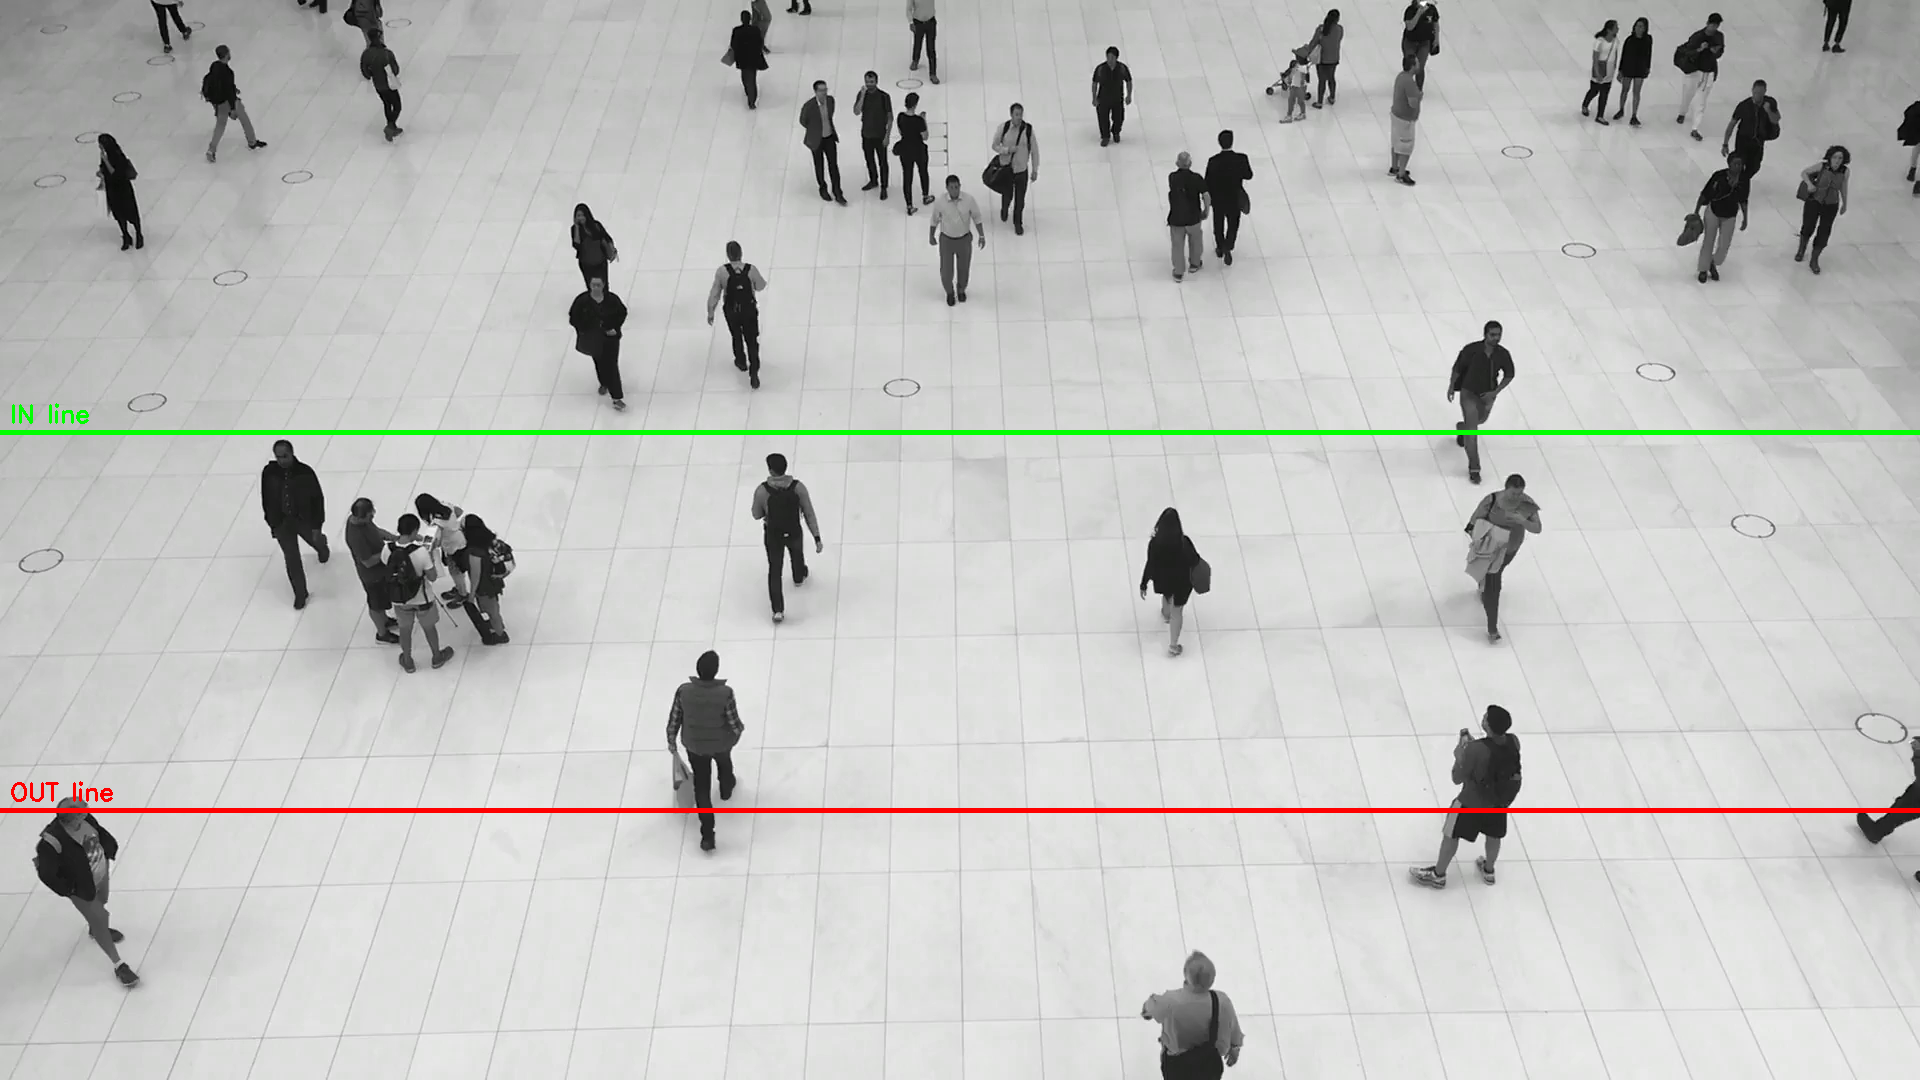

In [6]:
cap = cv2.VideoCapture(SOURCE_VIDEO_PATH)
ret, preview_frame = cap.read()
cap.release()

preview = preview_frame.copy()
cv2.line(preview, (LINE_UPPER_START.x, LINE_UPPER_START.y),
         (LINE_UPPER_END.x, LINE_UPPER_END.y), (0, 255, 0), 3)
cv2.line(preview, (LINE_LOWER_START.x, LINE_LOWER_START.y),
         (LINE_LOWER_END.x, LINE_LOWER_END.y), (0, 0, 255), 3)
cv2.putText(preview, "IN line", (10, max(LINE_UPPER_Y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
cv2.putText(preview, "OUT line", (10, LINE_LOWER_Y - 10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
cv2_imshow(preview)


REFERENCE_FRAME = preview_frame.copy()


## 7. Load YOLOv8 Detector & ByteTrack Multi-Object Tracker


In [7]:
import torch

try:
    from ultralytics.nn.tasks import DetectionModel
    torch.serialization.add_safe_globals([DetectionModel])
except Exception:
    pass

model = YOLO("yolov8n.pt")  # pretrained on COCO model

tracker = sv.ByteTrack(frame_rate=video_info.fps)
box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator(text_scale=0.5, text_thickness=1)

PERSON_CLASS_ID = 0


## 8. Initialize Directional Counters, State Trackers, and Heatmap Matrix


In [8]:
in_count = 0
out_count = 0

track_last_y = {}        # track_id -> last known foot (bottom-center) y position
counted_in_ids = set()   # track_ids already counted as IN
counted_out_ids = set()  # track_ids already counted as OUT

heat_matrix = np.zeros((FRAME_HEIGHT, FRAME_WIDTH), dtype=np.float32)


## 9. Execute Real-Time Stream Ingestion & Tracking Loop

Pipeline flow for each frame:
1. **Object Detection:** Infer bounding boxes with YOLOv8n (class_id == 0).
2. **Association:** Update ByteTrack Kalman filters to maintain persistent tracker_ids.
3. **Foot Anchor Extraction:** Compute bottom-center coordinate (cx, cy) = ((x1 + x2) / 2, y2).
4. **Directional Boundary Crossing:** Compare (prev_cy, curr_cy) against virtual lines with deduplication sets.
5. **Spatial Accumulation:** Increment circular footprint (radius=15) onto Float32 density matrix.
6. **Visual HUD Annotations:** Draw bounding boxes, IDs, tripwires, and live IN/OUT statistics.


In [9]:
frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)

with sv.VideoSink(target_path=OUTPUT_VIDEO_PATH, video_info=video_info) as sink:
    for frame in frame_generator:
        results = model(frame, verbose=False)[0]
        detections = sv.Detections.from_ultralytics(results)
        detections = detections[detections.class_id == PERSON_CLASS_ID]
        detections = tracker.update_with_detections(detections)

        annotated_frame = frame.copy()

        # draw the two counting lines
        cv2.line(annotated_frame, (LINE_UPPER_START.x, LINE_UPPER_START.y),
                 (LINE_UPPER_END.x, LINE_UPPER_END.y), (0, 255, 0), 2)
        cv2.line(annotated_frame, (LINE_LOWER_START.x, LINE_LOWER_START.y),
                 (LINE_LOWER_END.x, LINE_LOWER_END.y), (0, 0, 255), 2)

        if detections.tracker_id is not None and len(detections) > 0:
            labels = [f"ID {tid}" for tid in detections.tracker_id]
            annotated_frame = box_annotator.annotate(annotated_frame, detections)
            annotated_frame = label_annotator.annotate(annotated_frame, detections, labels=labels)

            for i in range(len(detections)):
                tid = int(detections.tracker_id[i])
                x1, y1, x2, y2 = detections.xyxy[i]
                cx = int((x1 + x2) / 2)
                cy = int(y2)


                cv2.circle(heat_matrix, (cx, cy), 15, 1.0, -1)

                if tid in track_last_y:
                    prev_cy = track_last_y[tid]

                    if prev_cy < LINE_UPPER_Y <= cy and tid not in counted_in_ids:
                        in_count += 1
                        counted_in_ids.add(tid)

                    if prev_cy > LINE_LOWER_Y >= cy and tid not in counted_out_ids:
                        out_count += 1
                        counted_out_ids.add(tid)

                track_last_y[tid] = cy


        cv2.rectangle(annotated_frame, (0, 0), (250, 75), (0, 0, 0), -1)
        cv2.putText(annotated_frame, f"IN: {in_count}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
        cv2.putText(annotated_frame, f"OUT: {out_count}", (10, 62),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

        sink.write_frame(annotated_frame)

print(f"Final counts -> IN: {in_count}, OUT: {out_count}")
print(f"Output video saved to: {OUTPUT_VIDEO_PATH}")


Final counts -> IN: 12, OUT: 9
Output video saved to: people_flow_output.mp4


## 10. Generate Gaussian Smoothed Spatial Heatmaps


Saved: final_heatmap_overlay.jpg, final_heatmap_pure.jpg


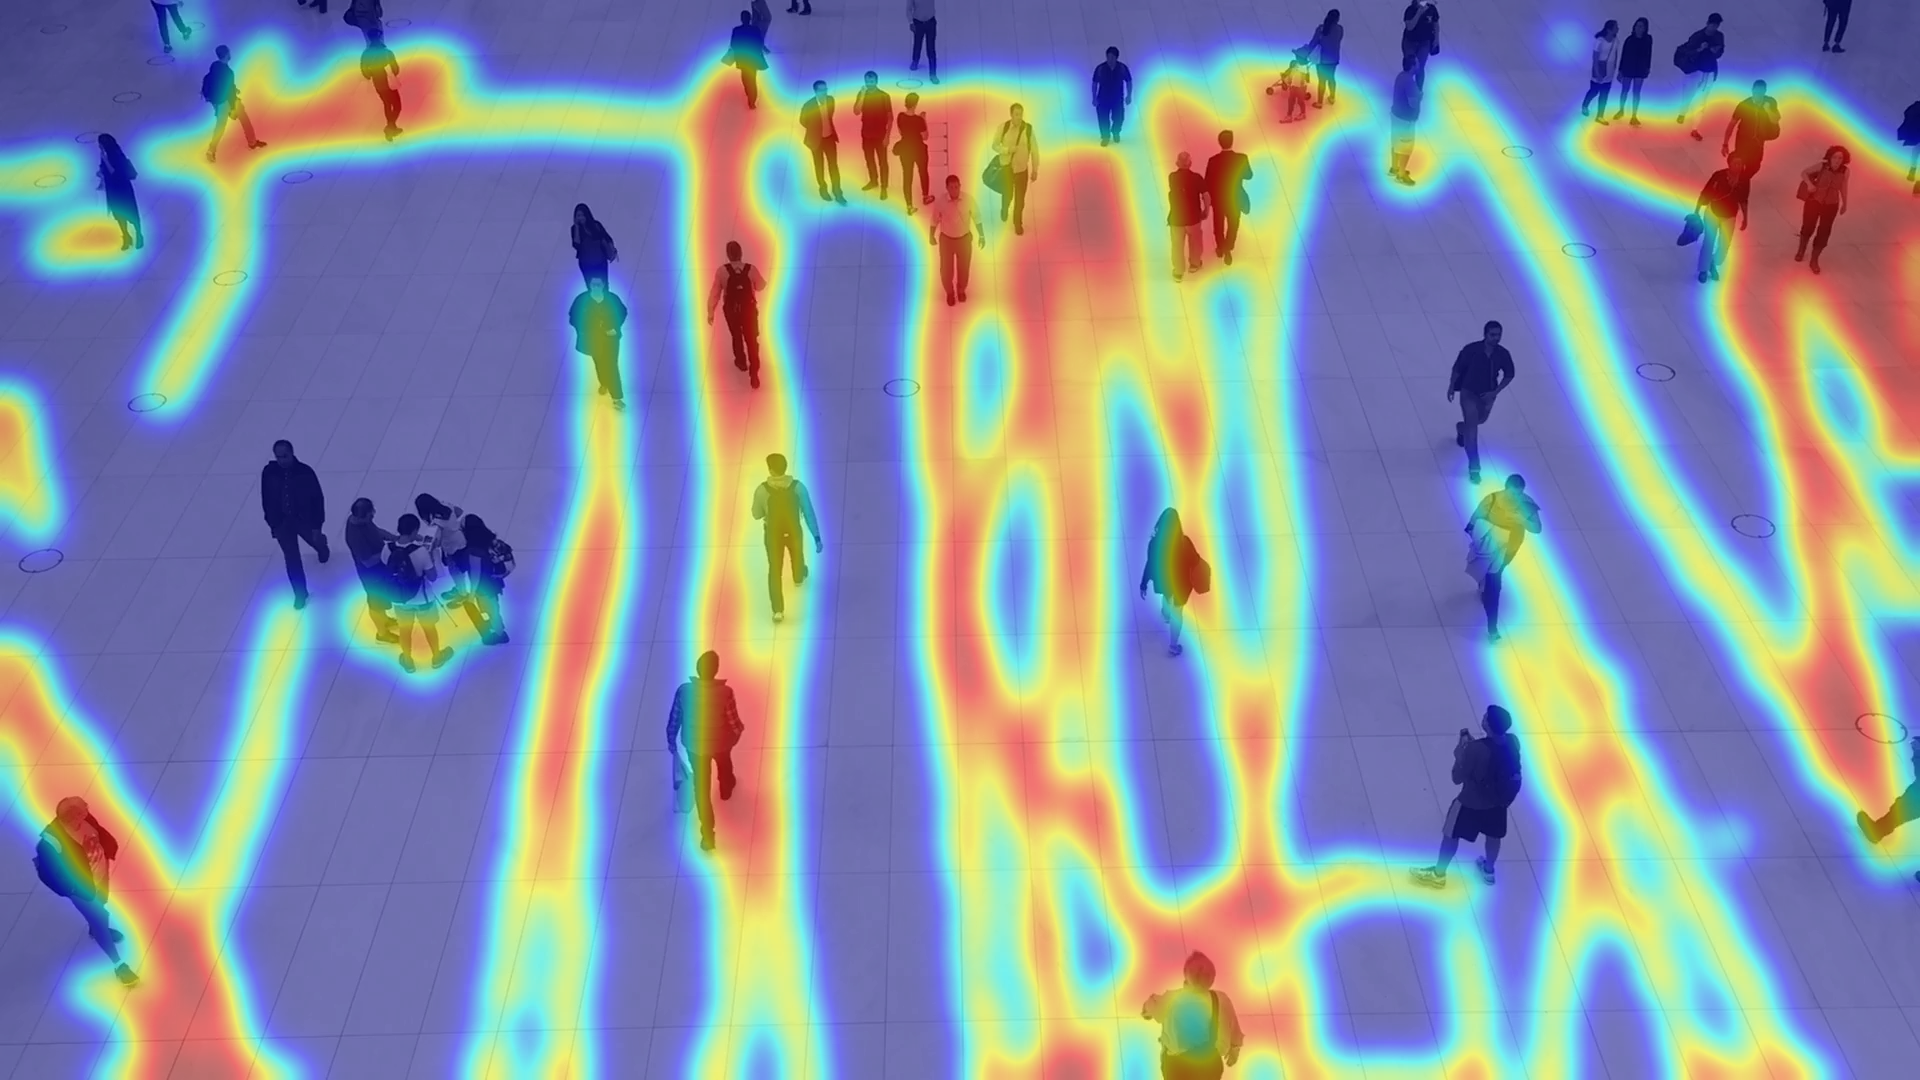

In [10]:
heat_blur = cv2.GaussianBlur(heat_matrix, (0, 0), sigmaX=20, sigmaY=20)
heat_norm = cv2.normalize(heat_blur, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
heat_color = cv2.applyColorMap(heat_norm, cv2.COLORMAP_JET)

# overlay heatmap on the first frame for spatial context
heatmap_overlay = cv2.addWeighted(REFERENCE_FRAME, 0.5, heat_color, 0.5, 0)

cv2.imwrite("final_heatmap_overlay.jpg", heatmap_overlay)
cv2.imwrite("final_heatmap_pure.jpg", heat_color)

print("Saved: final_heatmap_overlay.jpg, final_heatmap_pure.jpg")
cv2_imshow(heatmap_overlay)


## 11. Visualize Density Heatmap Results


Heatmap Overlay:


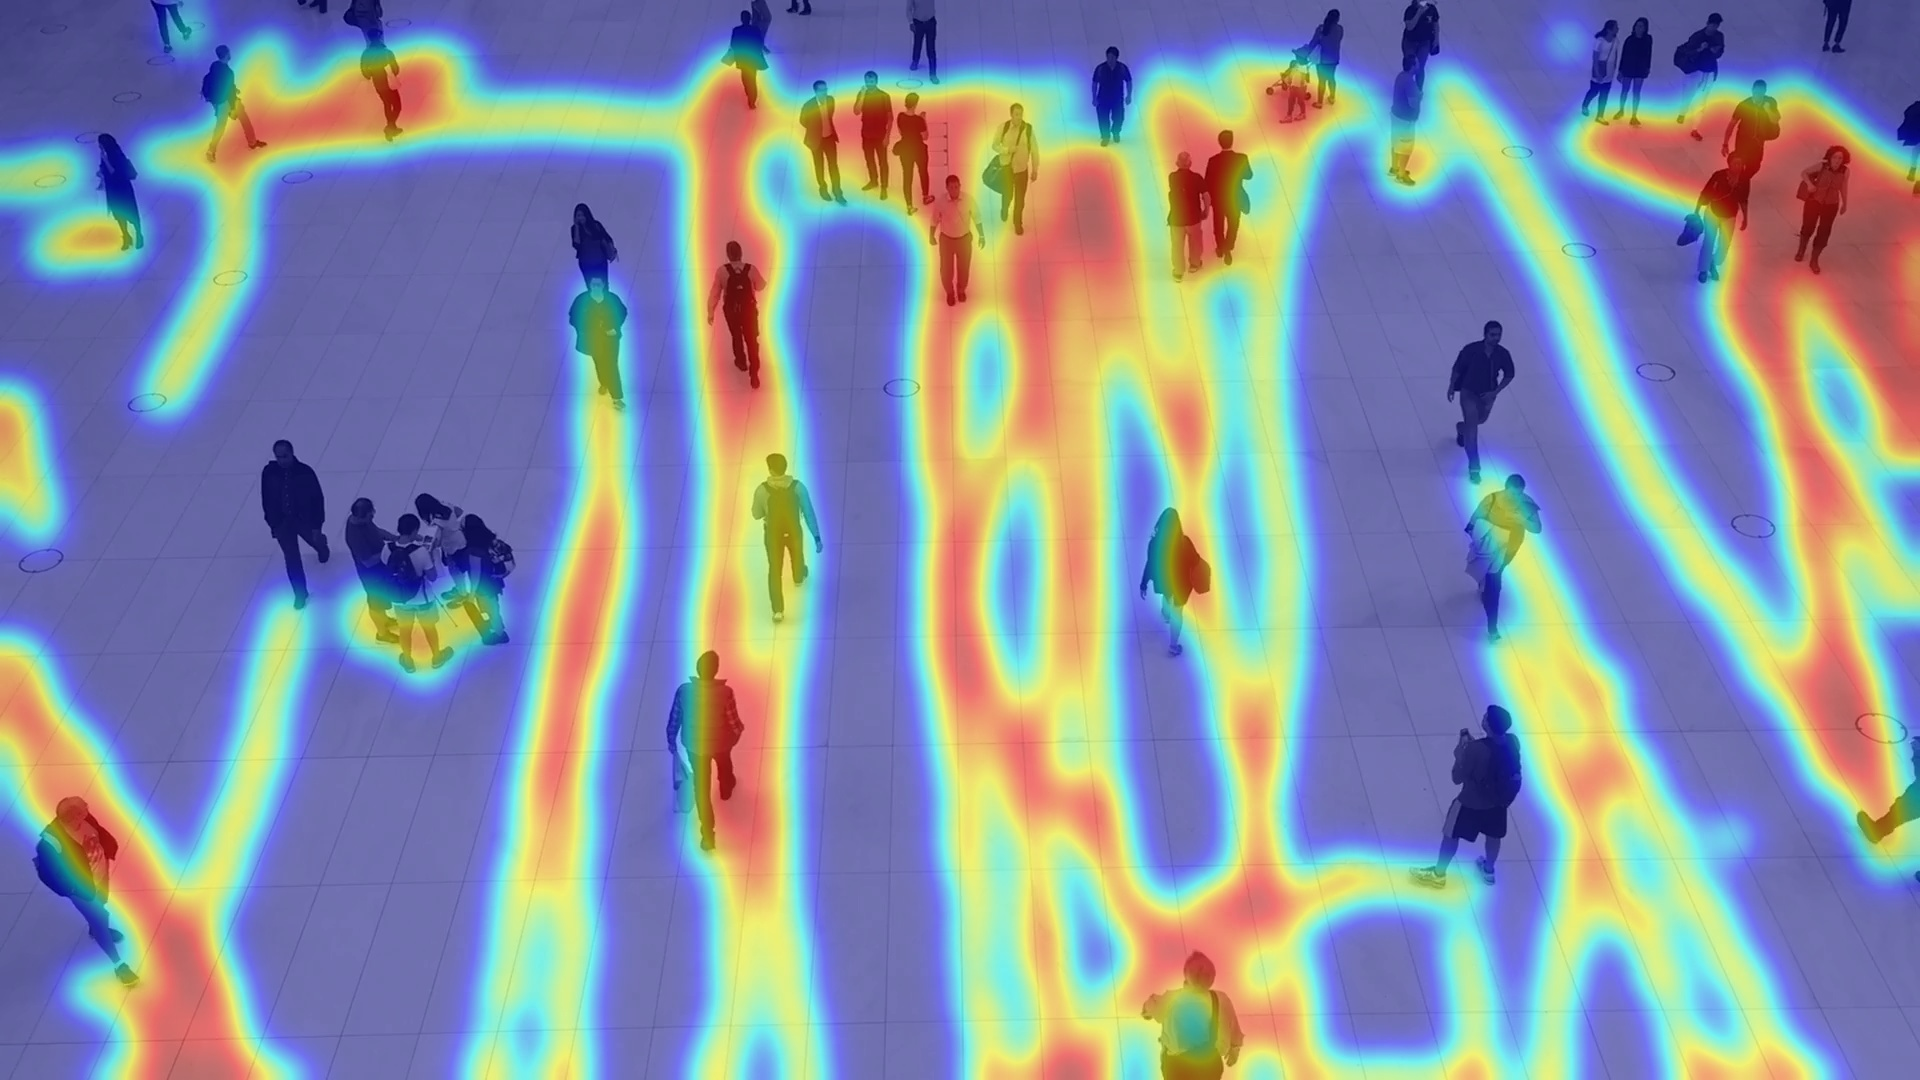

Pure Heatmap:


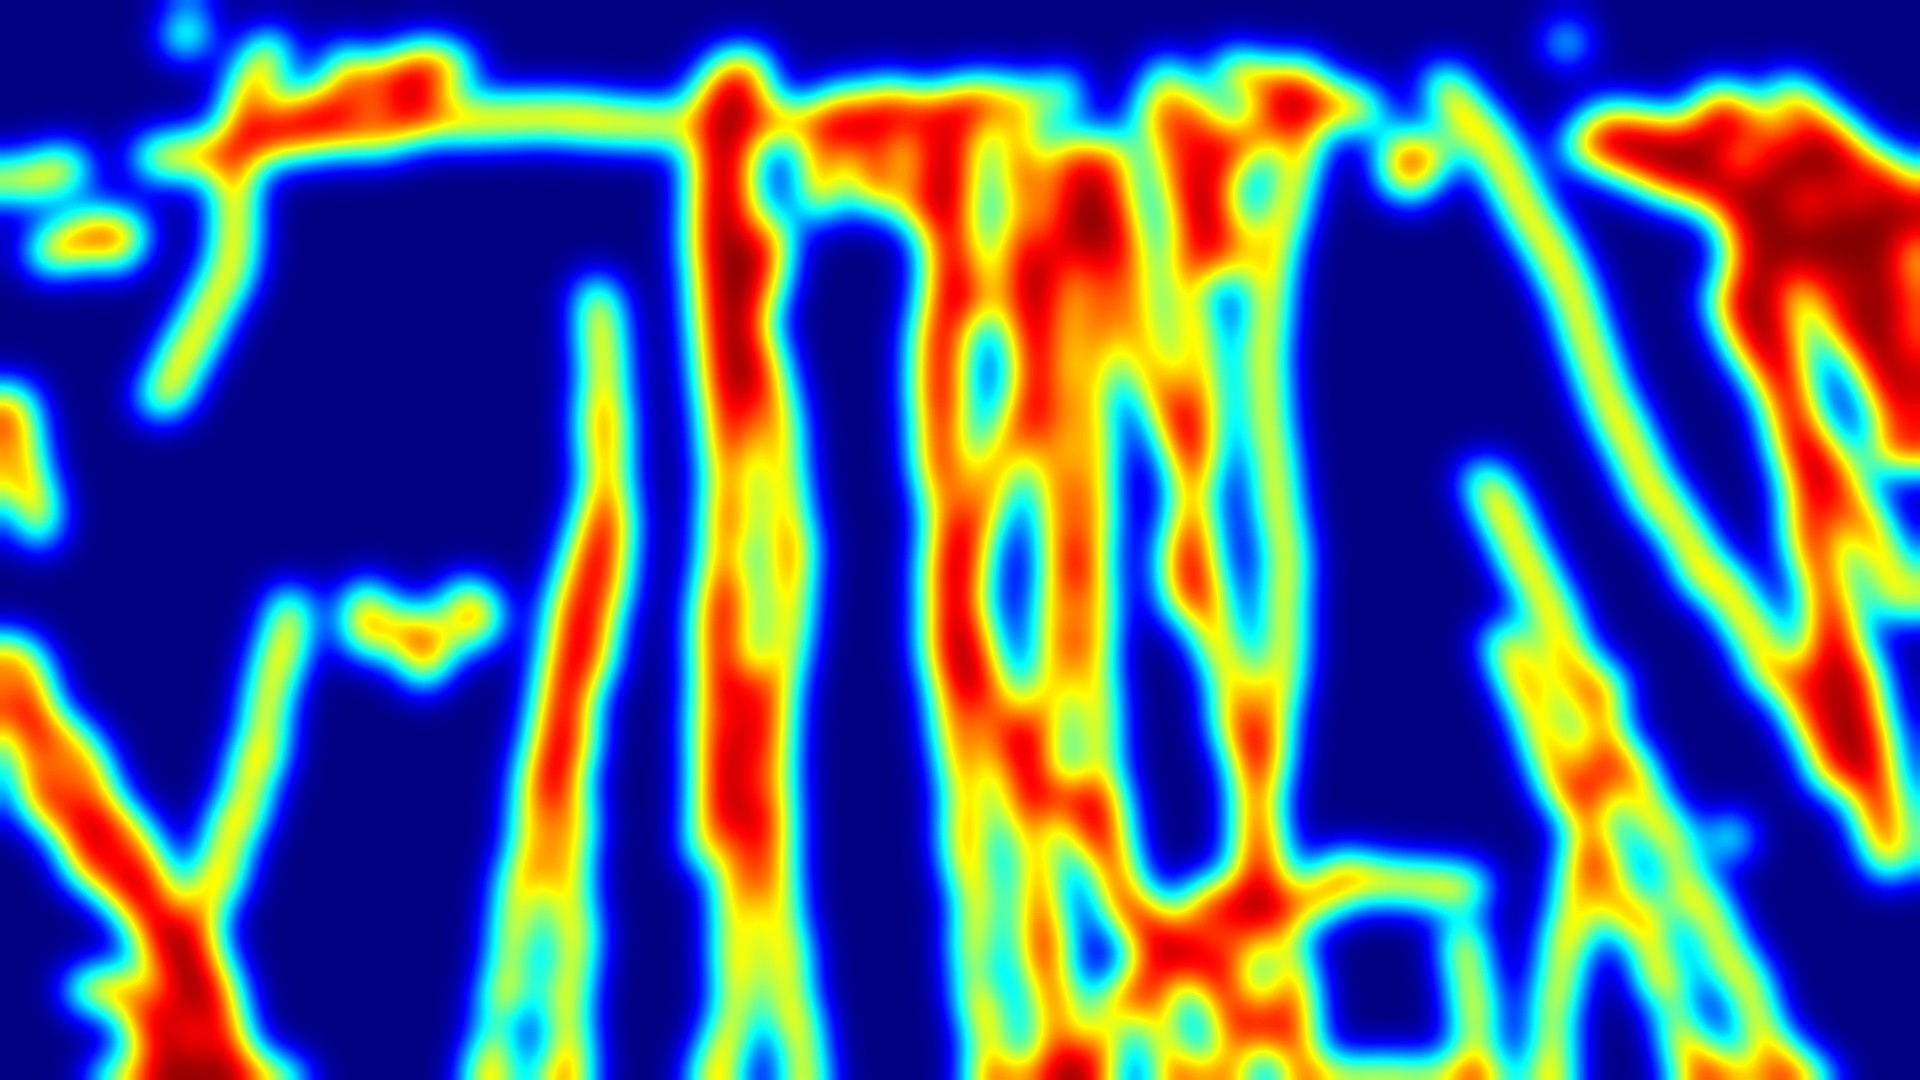

In [11]:
from IPython.display import Image, display

# Display the blended heatmap overlay
print("Heatmap Overlay:")
display(Image("final_heatmap_overlay.jpg", width=600))

# Display the raw heatmap
print("Pure Heatmap:")
display(Image("final_heatmap_pure.jpg", width=600))

## 12. Pipeline Summary & Verification


In [12]:
import os
print("Pipeline Execution Summary:")
print("---------------------------")
print(f"Total Frames Processed : {video_info.total_frames}")
print(f"Resolution             : {video_info.width}x{video_info.height} @ {video_info.fps} FPS")
print(f"Total IN Count         : {in_count}")
print(f"Total OUT Count        : {out_count}")
print(f"Annotated Video Output : {OUTPUT_VIDEO_PATH}")
print(f"Heatmap Overlay Output : final_heatmap_overlay.jpg")
print(f"Pure Heatmap Output    : final_heatmap_pure.jpg")


Pipeline Execution Summary:
---------------------------
Total Frames Processed : 375
Resolution             : 1920x1080 @ 25 FPS
Total IN Count         : 12
Total OUT Count        : 9
Annotated Video Output : people_flow_output.mp4
Heatmap Overlay Output : final_heatmap_overlay.jpg
Pure Heatmap Output    : final_heatmap_pure.jpg
